In [1]:
# import necessary libraries 
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import  os
from pathlib import  Path
from statsmodels.graphics.tsaplots import plot_acf

import holidays
import seaborn as sns


plt.style.use('dark_background')
plt.rcParams['axes.edgecolor'] = '#444444'
plt.rcParams['grid.color'] = '#333333'
plt.rcParams['grid.alpha'] = 0.8

In [2]:
path = "/Users/kwakye/Desktop/Github Projects/portfolio_project_one/gb-demand-imbalance-forecasting/data/processed/gb_demand_2009_2025.csv"

In [3]:
df = pd.read_csv(path)

In [4]:
#check shape of the dataset
df.shape

(298032, 17)

In [201]:
#check info of dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 298032 entries, 0 to 298031
Data columns (total 17 columns):
 #   Column                     Non-Null Count   Dtype 
---  ------                     --------------   ----- 
 0   SETTLEMENT_DATE            298032 non-null  object
 1   SETTLEMENT_PERIOD          298032 non-null  int64 
 2   ND                         298032 non-null  int64 
 3   TSD                        298032 non-null  int64 
 4   ENGLAND_WALES_DEMAND       298032 non-null  int64 
 5   EMBEDDED_WIND_GENERATION   298032 non-null  int64 
 6   EMBEDDED_WIND_CAPACITY     298032 non-null  int64 
 7   EMBEDDED_SOLAR_GENERATION  298032 non-null  int64 
 8   EMBEDDED_SOLAR_CAPACITY    298032 non-null  int64 
 9   NON_BM_STOR                298032 non-null  int64 
 10  PUMP_STORAGE_PUMPING       298032 non-null  int64 
 11  IFA_FLOW                   298032 non-null  int64 
 12  IFA2_FLOW                  298032 non-null  int64 
 13  BRITNED_FLOW               298032 non-null  

In [202]:
df = df[['SETTLEMENT_DATE','SETTLEMENT_PERIOD','ND','EMBEDDED_WIND_GENERATION','EMBEDDED_SOLAR_GENERATION','ENGLAND_WALES_DEMAND']].copy()

In [203]:
#check first few rows of dataset
df.head(5)

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,EMBEDDED_WIND_GENERATION,EMBEDDED_SOLAR_GENERATION,ENGLAND_WALES_DEMAND
0,2022-01-01,1,21940,2713,0,20513
1,2022-01-01,2,22427,2755,0,21021
2,2022-01-01,3,21896,2930,0,20619
3,2022-01-01,4,20693,3090,0,19615
4,2022-01-01,5,19481,3161,0,18545


In [204]:
#convert settlement_date to a datetime object
df["SETTLEMENT_DATE"] = pd.to_datetime(df["SETTLEMENT_DATE"],format="mixed", dayfirst=True)

# Create a full timestamp
df['datetime'] = df['SETTLEMENT_DATE'] + pd.to_timedelta((df['SETTLEMENT_PERIOD'] -1)*30,unit ='minutes')


df[["SETTLEMENT_DATE",'SETTLEMENT_PERIOD','datetime']].head()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,datetime
0,2022-01-01,1,2022-01-01 00:00:00
1,2022-01-01,2,2022-01-01 00:30:00
2,2022-01-01,3,2022-01-01 01:00:00
3,2022-01-01,4,2022-01-01 01:30:00
4,2022-01-01,5,2022-01-01 02:00:00


In [205]:
df = df.sort_values("datetime").reset_index(drop=True)

In [206]:
df.head()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,EMBEDDED_WIND_GENERATION,EMBEDDED_SOLAR_GENERATION,ENGLAND_WALES_DEMAND,datetime
0,2009-01-01,1,37910,54,0,33939,2009-01-01 00:00:00
1,2009-01-01,2,38047,53,0,34072,2009-01-01 00:30:00
2,2009-01-01,3,37380,53,0,33615,2009-01-01 01:00:00
3,2009-01-01,4,36426,50,0,32526,2009-01-01 01:30:00
4,2009-01-01,5,35687,50,0,31877,2009-01-01 02:00:00


In [207]:
#create time features
df['year'] = df['datetime'].dt.year
df['month'] = df['datetime'].dt.month
df['day_of_week'] = df['datetime'].dt.dayofweek
df["hour"] = df["datetime"].dt.hour
df["minute"] = df["datetime"].dt.minute
df["day_of_year"] = df["datetime"].dt.dayofyear
df['quarter'] = df['datetime'].dt.quarter
df["is_weekend"] = (df["datetime"].dt.dayofweek >= 5).astype(int)

In [208]:
#add holidys columms
uk_holidays = holidays.UnitedKingdom(years = range(2009,2026))
holiday_dates = pd.to_datetime(list(uk_holidays.keys()))
df["is_holiday"] = df["datetime"].dt.normalize().isin(holiday_dates).astype(int)

In [209]:
df = df.set_index('datetime')

In [210]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 298032 entries, 2009-01-01 00:00:00 to 2025-12-31 23:30:00
Data columns (total 15 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   SETTLEMENT_DATE            298032 non-null  datetime64[ns]
 1   SETTLEMENT_PERIOD          298032 non-null  int64         
 2   ND                         298032 non-null  int64         
 3   EMBEDDED_WIND_GENERATION   298032 non-null  int64         
 4   EMBEDDED_SOLAR_GENERATION  298032 non-null  int64         
 5   ENGLAND_WALES_DEMAND       298032 non-null  int64         
 6   year                       298032 non-null  int32         
 7   month                      298032 non-null  int32         
 8   day_of_week                298032 non-null  int32         
 9   hour                       298032 non-null  int32         
 10  minute                     298032 non-null  int32         
 11  day_of_year       

In [211]:
df.isnull().sum()

SETTLEMENT_DATE              0
SETTLEMENT_PERIOD            0
ND                           0
EMBEDDED_WIND_GENERATION     0
EMBEDDED_SOLAR_GENERATION    0
ENGLAND_WALES_DEMAND         0
year                         0
month                        0
day_of_week                  0
hour                         0
minute                       0
day_of_year                  0
quarter                      0
is_weekend                   0
is_holiday                   0
dtype: int64

In [212]:
df.describe()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,EMBEDDED_WIND_GENERATION,EMBEDDED_SOLAR_GENERATION,ENGLAND_WALES_DEMAND,year,month,day_of_week,hour,minute,day_of_year,quarter,is_weekend,is_holiday
count,298032,298032.000000,298032.000000,298032.000000,298032.000000,298032.000000,298032.000000,298032.000000,298032.000000,298032.000000,298032.000000,298032.000000,298032.000000,298032.000000,298032.000000
mean,2017-07-02 00:35:06.426155776,24.500228,30883.869618,1349.520645,966.294740,28127.100285,2017.000644,6.523924,2.999316,11.497376,15.000000,183.142387,2.508959,0.285600,0.019649
min,2009-01-01 00:00:00,1.000000,12803.000000,0.000000,0.000000,0.000000,2009.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,2013-04-02 00:00:00,12.750000,24593.000000,574.000000,0.000000,22409.000000,2013.000000,4.000000,1.000000,5.000000,0.000000,92.000000,2.000000,0.000000,0.000000
50%,2017-07-02 00:00:00,24.500000,30129.500000,1054.000000,0.000000,27431.000000,2017.000000,7.000000,3.000000,11.000000,15.000000,183.000000,3.000000,0.000000,0.000000
75%,2021-10-01 00:00:00,36.250000,36598.000000,1823.000000,982.000000,33337.000000,2021.000000,10.000000,5.000000,17.000000,30.000000,274.000000,4.000000,1.000000,0.000000
max,2025-12-31 00:00:00,50.000000,59095.000000,5962.000000,14046.000000,53325.000000,2025.000000,12.000000,6.000000,23.000000,30.000000,366.000000,4.000000,1.000000,1.000000
std,NaN,13.853818,7824.215256,1055.507771,1896.539826,7079.604244,4.898790,3.448669,2.000003,6.922198,15.000025,105.437259,1.117063,0.451701,0.138791


In [213]:
#check summary statistics for the demand column for each year
df[['ND','year']].groupby(by ='year')['ND'].agg(Mean ='mean',STD ='std', Max ='max',Min ='min').round()

,Mean,STD,Max,Min
year,,,,
2009,35919.0,7760.0,58594,19557
2010,36535.0,8144.0,59095,19424
2011,35150.0,7605.0,55113,19347
2012,35181.0,7442.0,55765,19219
2013,34885.0,7603.0,55572,18555
2014,33169.0,7143.0,51208,18074
2015,32223.0,7104.0,52516,17909
2016,31375.0,7022.0,51102,16396
2017,30373.0,7011.0,49883,16574


In [214]:
#check for duplicates
duplicate_rows  = df[df.duplicated()]
duplicate_rows 

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,EMBEDDED_WIND_GENERATION,EMBEDDED_SOLAR_GENERATION,ENGLAND_WALES_DEMAND,year,month,day_of_week,hour,minute,day_of_year,quarter,is_weekend,is_holiday
datetime,,,,,,,,,,,,,,,


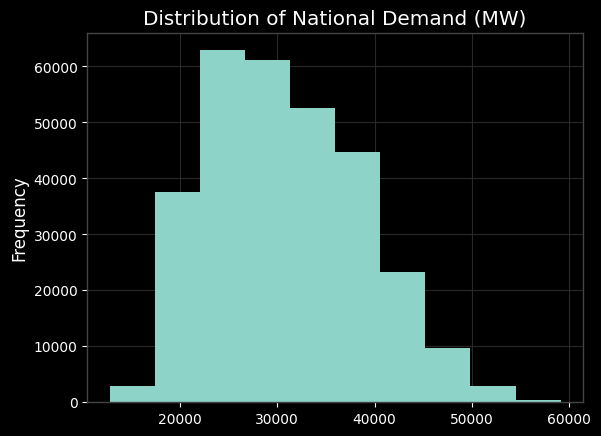

In [215]:
#check demand distribution 
df['ND'].hist()
plt.title("Distribution of National Demand (MW)")
plt.ylabel("Frequency")
plt.show()

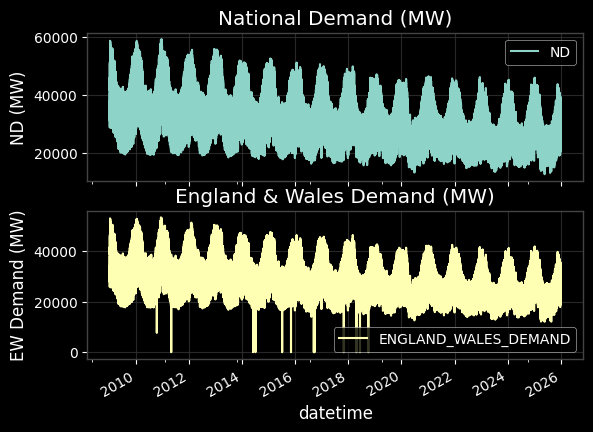

In [216]:
ax = df[['ND','ENGLAND_WALES_DEMAND']].plot(subplots=True)
ax[0].set_title("National Demand (MW)")
ax[0].set_ylabel("ND (MW)")
ax[1].set_title("England & Wales Demand (MW)")
ax[1].set_ylabel("EW Demand (MW)")
plt.show()

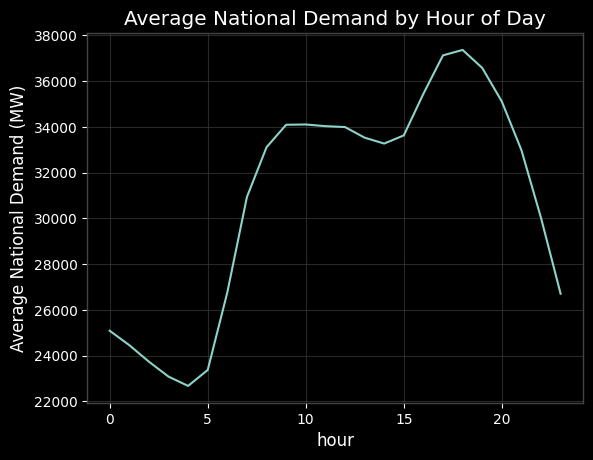

In [217]:
#daily pattern 
hourly_demand = df.groupby('hour')['ND'].mean()

hourly_demand.plot()
plt.title("Average National Demand by Hour of Day")
plt.ylabel("Average National Demand (MW)")
plt.show()

In [218]:
#Demand was quite low during the periods between 3 am to 5 am
#Demand started rising after 5 am and plateaued at 10 am before rising and peaking at around 6pm
# demand kept falling from evening to morning 

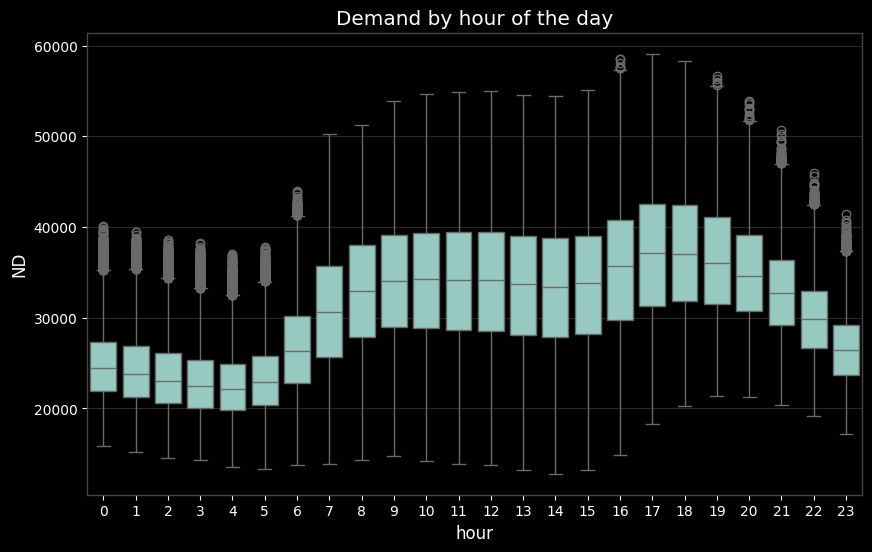

In [219]:
plt.figure(figsize = (10,6))
sns.boxplot(data = df,x = 'hour', y='ND',)
plt.title('Demand by hour of the day')
plt.show()

In [220]:
#weekly pattern
day_names = {0: 'Monday', 1: 'Tuesday', 2: 'Wednesday', 3: 'Thursday', 4: 'Friday', 5: 'Saturday', 6: 'Sunday'}
daily_avg = df.groupby('day_of_week')['ND'].mean()


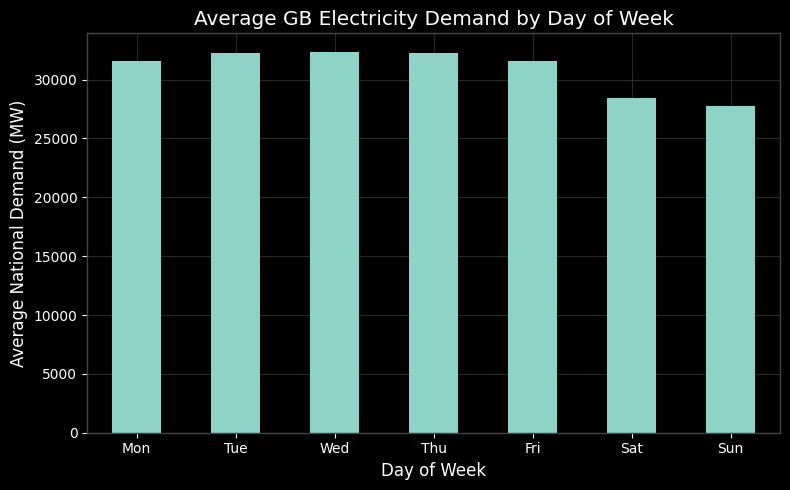

In [221]:

days = ["Mon", "Tue", "Wed","Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(8, 5))

daily_avg.plot(kind="bar", ax=ax)

ax.set_xticks(range(len(days)))
ax.set_xticklabels(days, rotation=0)

ax.set_xlabel("Day of Week")
ax.set_ylabel("Average National Demand (MW)")
ax.set_title("Average GB Electricity Demand by Day of Week")

plt.tight_layout()
plt.show()

In [222]:
weekday_hourly = df[df["is_weekend"] == 0].groupby("hour")["ND"].mean()
weekend_hourly = df[df["is_weekend"] == 1].groupby("hour")["ND"].mean()


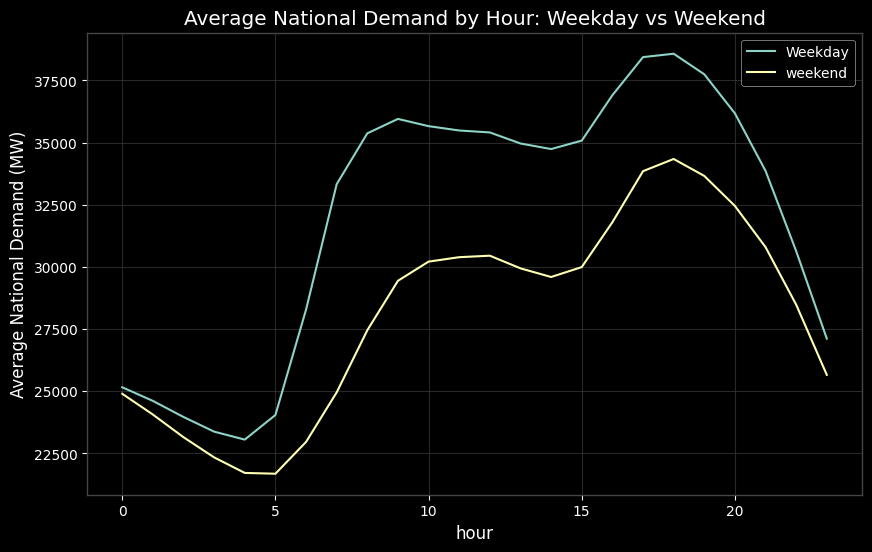

In [223]:
fig, ax = plt.subplots(figsize = (10,6))
weekday_hourly.plot(ax=ax, label= 'Weekday')
weekend_hourly.plot(ax=ax,label= 'weekend')
ax.set_title("Average National Demand by Hour: Weekday vs Weekend")
ax.set_ylabel("Average National Demand (MW)")
plt.legend()
plt.show()

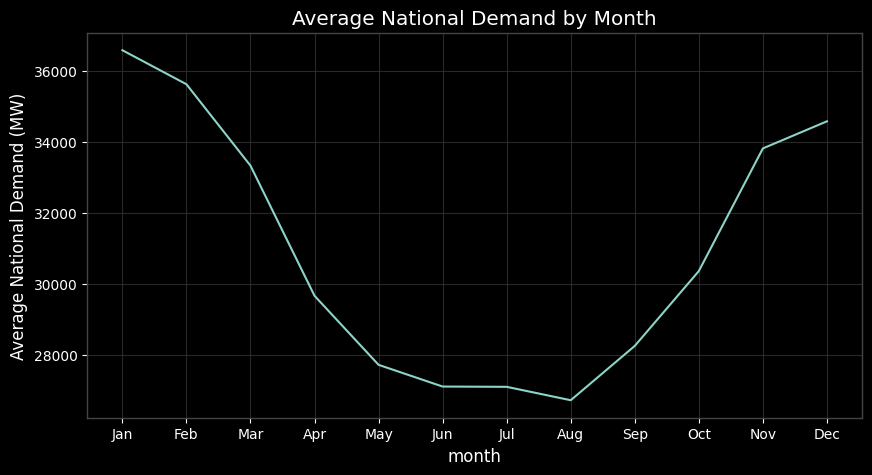

In [224]:
#monthly pattern 

monthly_avg = df.groupby("month")["ND"].mean()
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun","Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize =(10,5))
monthly_avg.plot(ax=ax)
ax.set_xticks(monthly_avg.index)
ax.set_xticklabels(months, rotation = 0)
ax.set_title("Average National Demand by Month")
ax.set_ylabel("Average National Demand (MW)")
plt.show()

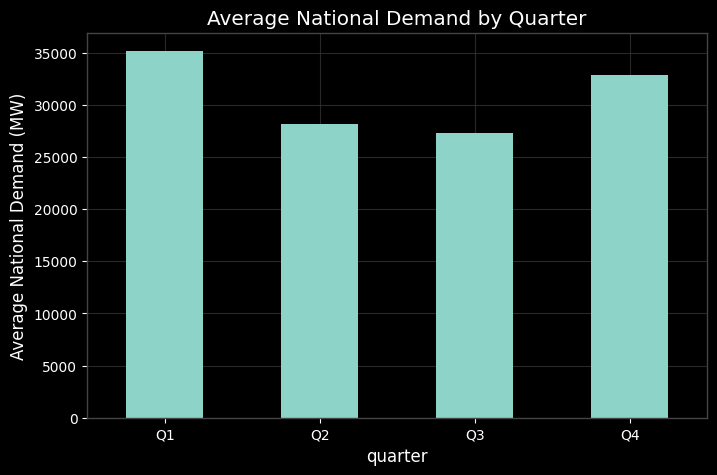

In [225]:
quaterly_avg = df.groupby('quarter')['ND'].mean()
fig, ax = plt.subplots(figsize=(8, 5))
quaterly_avg.plot(kind = 'bar', ax=ax)
ax.set_xticks(range(4))
ax.set_xticklabels(["Q1", "Q2", "Q3", "Q4"], rotation=0)
ax.set_title("Average National Demand by Quarter")
ax.set_ylabel("Average National Demand (MW)")
plt.show()

In [226]:
#yearly demand 
yearly_avg = df.groupby("year")["ND"].mean()

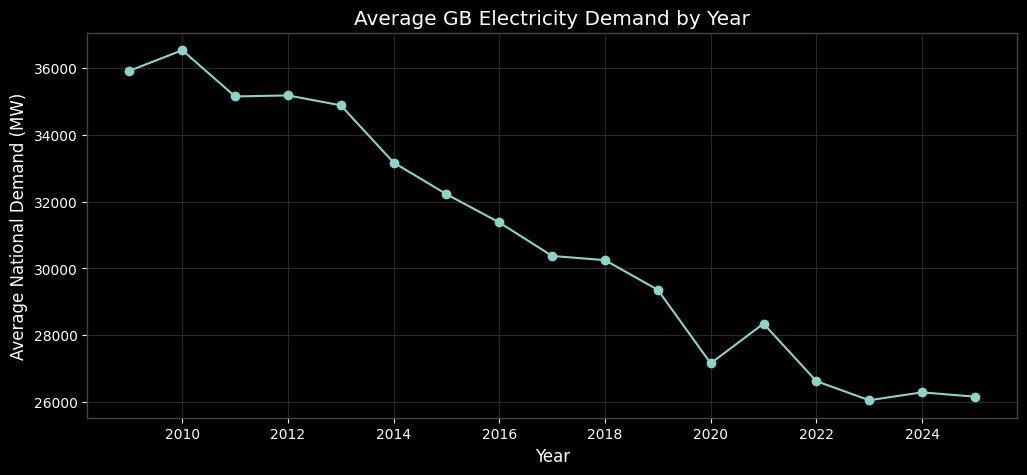

In [227]:
fig, ax = plt.subplots(figsize=(12,5))

yearly_avg.plot(ax=ax,marker="o")

ax.set_title("Average GB Electricity Demand by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Average National Demand (MW)")

plt.show()

In [228]:
yearly_avg_wind = df.groupby("year")["EMBEDDED_WIND_GENERATION"].mean()
yearly_avg_solar = df.groupby('year')['EMBEDDED_SOLAR_GENERATION'].mean()

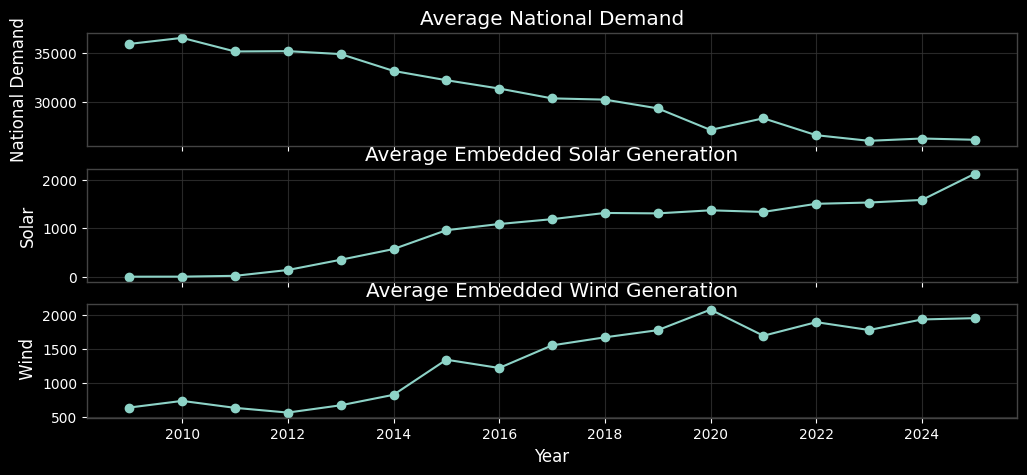

In [229]:
fig, ax = plt.subplots(figsize=(12,5),nrows=3, ncols= 1, sharex=True)

yearly_avg.plot(ax=ax[0],marker="o", label = 'ND')
ax[0].set_title('Average National Demand')
ax[0].set_ylabel('National Demand')
yearly_avg_solar.plot(ax=ax[1],marker="o",label ='Solar')
ax[1].set_ylabel('Solar')
ax[1].set_title('Average Embedded Solar Generation')
yearly_avg_wind.plot(ax=ax[2],marker="o",label ='Wind')
ax[2].set_ylabel(' Wind')
ax[2].set_title('Average Embedded Wind Generation')

ax[2].set_xlabel("Year")
plt.show()

In [230]:
# check correlation
#corr = df[['ND','EMBEDDED_SOLAR_GENERATION','EMBEDDED_WIND_GENERATION']].corr()

#sns.heatmap(corr,annot=True,fmt=".2f",cmap="rocket",center=0,square=True)

<Figure size 1500x500 with 0 Axes>

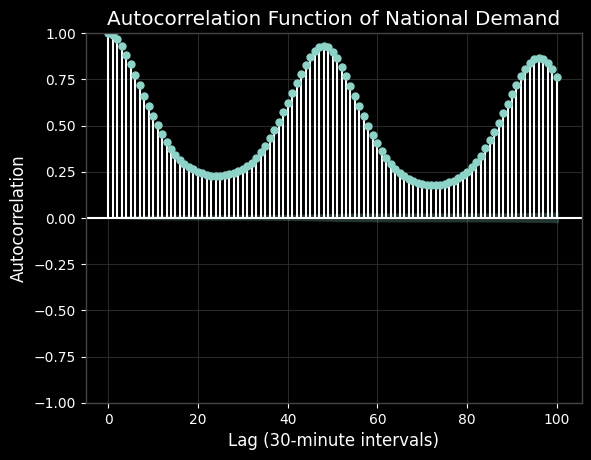

In [238]:
#add lag features
plt.figure(figsize=(15, 5))

plot_acf(df["ND"],lags= 100)

plt.title("Autocorrelation Function of National Demand")
plt.xlabel("Lag (30-minute intervals)")
plt.ylabel("Autocorrelation")

plt.show()

In [233]:
#create lags of 24h and weekly
df['lag_24h'] = df['ND'].shift(48)
df['lag_168h'] = df['ND'].shift(336)

In [234]:
df.iloc[329:350].head(30)

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,EMBEDDED_WIND_GENERATION,EMBEDDED_SOLAR_GENERATION,ENGLAND_WALES_DEMAND,year,month,day_of_week,hour,minute,day_of_year,quarter,is_weekend,is_holiday,lag_24h,lag_168h
datetime,,,,,,,,,,,,,,,,,
2009-01-07 20:30:00,2009-01-07,42,50014,152,0,45242,2009,1,2,20,30,7,1,0,0,51282.0,NaN
2009-01-07 21:00:00,2009-01-07,43,48340,152,0,43683,2009,1,2,21,0,7,1,0,0,49370.0,NaN
2009-01-07 21:30:00,2009-01-07,44,46236,112,0,41805,2009,1,2,21,30,7,1,0,0,47010.0,NaN
2009-01-07 22:00:00,2009-01-07,45,43706,112,0,39432,2009,1,2,22,0,7,1,0,0,44653.0,NaN
2009-01-07 22:30:00,2009-01-07,46,41520,110,0,37274,2009,1,2,22,30,7,1,0,0,42281.0,NaN
2009-01-07 23:00:00,2009-01-07,47,39085,110,0,35074,2009,1,2,23,0,7,1,0,0,39576.0,NaN
2009-01-07 23:30:00,2009-01-07,48,37606,114,0,33855,2009,1,2,23,30,7,1,0,0,38394.0,NaN
2009-01-08 00:00:00,2009-01-08,1,38055,114,0,34394,2009,1,3,0,0,8,1,0,0,38746.0,37910.0
2009-01-08 00:30:00,2009-01-08,2,37957,156,0,34331,2009,1,3,0,30,8,1,0,0,38615.0,38047.0


In [235]:
#rolling features 
df['roll_mean_24h'] = df['ND'].shift(1).rolling(window = 48).mean()
df['roll_mean_168h'] = df['ND'].shift(1).rolling(window = 336).mean()
df['roll_std_24h'] = df['ND'].shift(1).rolling(window = 48).std()
df['roll_std_168h'] = df['ND'].shift(1).rolling(window = 336).std()

In [236]:
df.isnull().sum()

SETTLEMENT_DATE                0
SETTLEMENT_PERIOD              0
ND                             0
EMBEDDED_WIND_GENERATION       0
EMBEDDED_SOLAR_GENERATION      0
ENGLAND_WALES_DEMAND           0
year                           0
month                          0
day_of_week                    0
hour                           0
minute                         0
day_of_year                    0
quarter                        0
is_weekend                     0
is_holiday                     0
lag_24h                       48
lag_168h                     336
roll_mean_24h                 48
roll_mean_168h               336
roll_std_24h                  48
roll_std_168h                336
dtype: int64

In [ ]:
#drop na values 
data = df.dropna().copy()

#drop features not being used
data.drop(columns=['SETTLEMENT_DATE','EMBEDDED_WIND_GENERATION','EMBEDDED_SOLAR_GENERATION','ENGLAND_WALES_DEMAND'],inplace=True)



In [239]:
data.isnull().sum()

SETTLEMENT_PERIOD    0
ND                   0
year                 0
month                0
day_of_week          0
hour                 0
minute               0
day_of_year          0
quarter              0
is_weekend           0
is_holiday           0
lag_24h              0
lag_168h             0
roll_mean_24h        0
roll_mean_168h       0
roll_std_24h         0
roll_std_168h        0
dtype: int64